# Water saturation

Water saturation is the fraction of the pore space filled with water; one minus it is
hydrocarbon. It comes from resistivity: rock framework and hydrocarbons don't conduct, only the
brine in the pores does, so a resistive zone at good porosity is a hydrocarbon flag. Archie's
equation makes that quantitative, given the formation-water resistivity `Rw` and two exponents
(`m` for cementation, `n` for saturation).

Archie assumes the only conductor is brine. That breaks in shaly sands, where clay conducts too, 
so the library also carries Simandoux, Indonesia, and Waxman-Smits, which add a clay term. The
workflow picks `Rw` and the model for you.

## Archie's equation

Resistivity ties to saturation through Archie's law,

$$S_w = \left(\frac{a\,R_w}{\phi^{m}\,R_t}\right)^{1/n}$$

where $R_t$ is the measured (true) resistivity, $R_w$ the formation-water resistivity, $\phi$ the
effective porosity, $a$ the tortuosity factor, $m$ the cementation exponent, and $n$ the saturation
exponent. It assumes brine is the only conductor, so in shaly sands the library switches to forms
that add a clay-conduction term (Simandoux, Indonesia, Waxman-Smits). A Pickett plot is just this
equation on log-log axes: $\log R_t$ against $\log \phi$ falls on a straight line of slope $-m$ at
fixed $S_w$.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
WELL = REPO / "petrophys" / "data" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
import numpy as np
well = read_las(WELL)
result = run_dynamic_workflow(well, lithology="clastic")   # computes PHIE, Rw, and SW
print("Rw used (ohm.m):", round(float(np.nanmedian(well.get("RW").data)), 4))
print("median SW:", round(float(np.nanmedian(well.get("SW").data)), 2))

Rw used (ohm.m): 0.1567
median SW: 0.93


The cleanest way to sanity-check `Rw`, `m`, and the saturation is a Pickett plot, resistivity
against porosity on log-log axes. Water-bearing points line up along the `Sw = 1` line; its
position fixes `Rw` and its slope fixes `m`. Points lifting above that line, higher resistivity at the same porosity, are hydrocarbon-bearing.

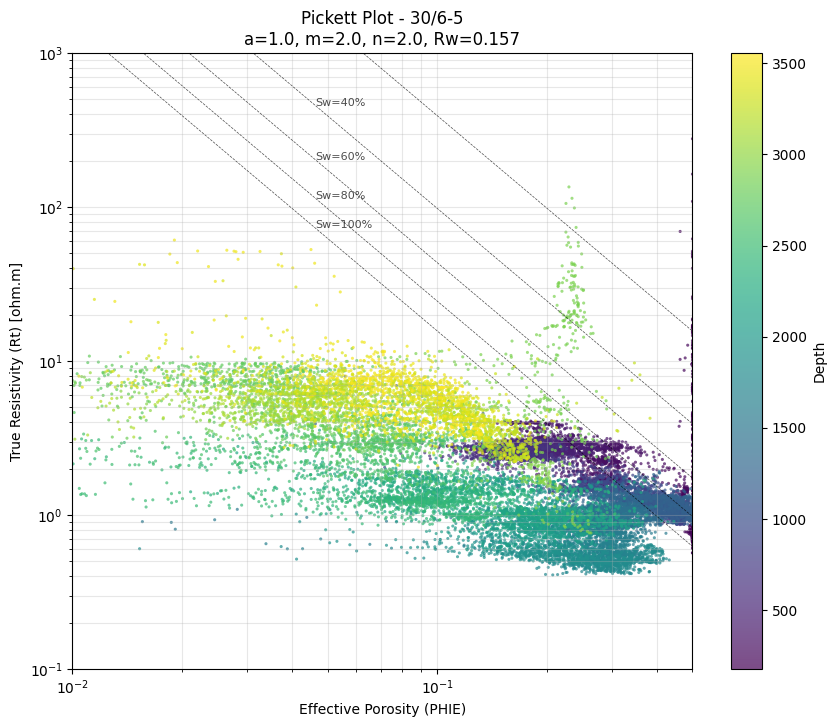

In [2]:
from petrophys.visualization import create_pickett_plot
create_pickett_plot(well, rw=float(__import__('numpy').nanmedian(well.get("RW").data)),
                    phie_curve="PHIE", rt_curve="RDEP");

If most points hug the `Sw = 1` line, the well is wet and `Rw` is about right; a cloud lifting
off it is a hydrocarbon column. Getting `Rw` wrong shifts everything, which is why the workflow
derives it from the data and records how. See the *core calibration* deep dive, where this is
validated against wells the regulator confirmed as dry or producing.